# Choice unpredictability along LD1, and its link to syllable use

**Why.** Along LD1 the K=2 GLM-HMM switch count differs (`fig_engagement` g/h). But that count survives shuffling trial order within a session: what it counts is how many choices stray from the engaged policy, not how they are ordered in time. The HMM does pick up real slow disengaged bouts, but that order information is flat along LD1. So the interpretable claim is about **choices**: are choices at the switchy end of LD1 less predictable, i.e. less stereotyped?

**Measure** (`choice_predictability.py`; no hidden states). Cross-entropy of a session's choices, in bits/trial, over the first 400 trials:
* `ce_engaged`: under the mouse's **engaged-state** GLM weights, i.e. how far choices stray from the mouse's own engaged policy (weights fit on all of the mouse's sessions).
* `ce_glm`: under a plain GLM fit on the mouse's **other** sessions (held out), i.e. how unpredictable choices are given the mouse's average policy.
* Each is also split into easy (≥ 25 %), hard (6.25/12.5 %) and zero-contrast trials. On easy trials the cross-entropy is mostly lapses; on hard trials it also reflects psychometric slope.

**Questions.**
1. Does choice unpredictability track LD1, and does it survive easy-trial accuracy (`p_easy`)?
2. Does it account for the switches–LD1 link?
3. Does it go with behavioural (syllable / trial-mode) variability, beyond what both share with LD1?

**Conventions** (as `fig_engagement_syllables`): mice are the unit (session values averaged within mouse), Spearman. Also lab-centred and within-mouse. LD1's sign is arbitrary between files, so section 1 prints which end is the switchy one.

In [1]:
import sys, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

REPO = pathlib.Path.cwd().resolve()
while not (REPO / 'Functions' / 'trial_modes.py').exists() and REPO != REPO.parent:
    REPO = REPO.parent
PI = REPO / 'paper-individuality'
for p in [PI, PI / 'GLM-HMM', PI / 'GLM-HMM' / 'transition_prediction']:
    sys.path.insert(0, str(p))
import paper_style as ps
import tp_data as td
import choice_predictability as cp
ps.use('paper')
pd.set_option('display.width', 160)

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


## Parameters

In [2]:
RECOMPUTE = False      # True reruns choice_predictability.main() (~10 s); otherwise reads its parquet caches
N_TRUNC = cp.N_TRUNC   # switches counted over the same first 400 trials as the cross-entropies

## 1. Data

* `ce`: per-session cross-entropies (`choice_entropy.parquet`). 242 sessions / 54 mice: a mouse needs a second session for the held-out GLM.
* `ent`: per-session trial-mode entropy `H_modes` and syllable entropy `H_syl` (`behaviour_entropy.parquet`), with the estimators of `fig_engagement_syllables` G/I.
* `switches`: flips of the most probable K=2 state over the first 400 trials (`fig_engagement` G).

In [3]:
if RECOMPUTE:
    cp.main()
ce = pd.read_parquet(cp.OUT / 'choice_entropy.parquet')
ent = pd.read_parquet(cp.OUT / 'behaviour_entropy.parquet')
lda = td.load_lda()

st = pd.read_parquet(cp.STATES_PATH)
st = st[st.groupby('eid').cumcount() < N_TRUNC]
sw = (st.assign(eng=st['p_state1'] >= 0.5).groupby('eid')['eng']
        .apply(lambda e: int((e.to_numpy()[1:] != e.to_numpy()[:-1]).sum())).rename('switches'))

S = (ce.merge(lda, on=['session', 'mouse_name'])
       .merge(ent, on='session', how='left')
       .merge(sw, left_on='session', right_index=True, how='left'))
print(f"{len(S)} sessions, {S['mouse_name'].nunique()} mice; entropies for {S['H_modes'].notna().sum()} sessions")
r = spearmanr(S.groupby('mouse_name')['lda_1'].mean(), S.groupby('mouse_name')['switches'].mean())
SWITCHY = 'low' if r.statistic < 0 else 'high'
print(f"switches vs LD1 (mice): rho = {r.statistic:.2f} -> the switchy end is {SWITCHY.upper()} LD1 in this file")

242 sessions, 54 mice; entropies for 242 sessions
switches vs LD1 (mice): rho = -0.38 -> the switchy end is LOW LD1 in this file


### Statistics helpers

`rho_table`: mouse-level Spearman of each measure with `x`; the same with `x` and the measure lab-centred (lab means removed across mice); and within mouse (both centred on the mouse mean, sessions as units, mice with ≥ 2 sessions). `partial`: mouse-level Spearman of the residuals after regressing the covariates out of both (linear, on ranks).

In [4]:
def to_mouse(d, cols):
    return d.groupby('mouse_name').agg({**{c: 'mean' for c in cols}, 'lab': 'first'})

def rho_table(d, x, ys):
    m = to_mouse(d, [x] + ys)
    rows = []
    for y in ys:
        mm = m[[x, y, 'lab']].dropna()
        lc = mm[[x, y]] - mm.groupby('lab')[[x, y]].transform('mean')
        w = d[['mouse_name', x, y]].dropna()
        w = w[w.groupby('mouse_name')[y].transform('size') > 1]
        wc = w[[x, y]] - w.groupby('mouse_name')[[x, y]].transform('mean')
        r, rl, rw = spearmanr(mm[x], mm[y]), spearmanr(lc[x], lc[y]), spearmanr(wc[x], wc[y])
        rows.append(dict(y=y, n_mice=len(mm), rho=r.statistic, p=r.pvalue, rho_lab_centred=rl.statistic,
                         p_lab_centred=rl.pvalue, rho_within=rw.statistic, p_within=rw.pvalue))
    return pd.DataFrame(rows).set_index('y')

def resid(y, X):
    X = np.column_stack([np.ones(len(y))] + [np.asarray(v, float) for v in X])
    return y - X @ np.linalg.lstsq(X, y, rcond=None)[0]

def partial(m, x, y, covs):
    mm = m[[x, y] + covs].dropna().rank()
    r = spearmanr(resid(mm[x].to_numpy(), [mm[c] for c in covs]), resid(mm[y].to_numpy(), [mm[c] for c in covs]))
    return r.statistic, r.pvalue, len(mm)

## 2. Does choice unpredictability track LD1?

The whole session, then by trial type, for both references. Expected if the switches result is about choices: the measures should track LD1 in the same direction as switches (more unpredictable at the switchy end).

In [5]:
CE = ['ce_engaged', 'ce_glm']
CE_TT = [f'{c}_{t}' for c in CE for t in cp.TRIAL_TYPES]
print(rho_table(S, 'lda_1', ['switches', 'p_easy'] + CE + CE_TT).round(3).to_string())

                 n_mice    rho      p  rho_lab_centred  p_lab_centred  rho_within  p_within
y                                                                                          
switches             54 -0.383  0.004           -0.485          0.000       0.079     0.220
p_easy               54  0.371  0.006            0.363          0.007       0.053     0.413
ce_engaged           54 -0.384  0.004           -0.372          0.006       0.045     0.490
ce_glm               54 -0.241  0.080           -0.257          0.060       0.122     0.058
ce_engaged_easy      54 -0.463  0.000           -0.406          0.002       0.020     0.756
ce_engaged_hard      54 -0.005  0.974           -0.077          0.581       0.097     0.131
ce_engaged_zero      54  0.217  0.114            0.145          0.294       0.190     0.003
ce_glm_easy          54 -0.382  0.004           -0.341          0.012       0.040     0.537
ce_glm_hard          54 -0.031  0.822           -0.107          0.441       0.11

### Beyond easy-trial accuracy

Easy-trial lapses are part of the cross-entropy by construction. The part that would make "less stereotyped" more than "less accurate" is what survives partialling `p_easy` out of both LD1 and the measure.

In [6]:
M = to_mouse(S, ['lda_1', 'switches', 'p_easy', 'H_modes', 'H_syl'] + CE + CE_TT)
rows = [dict(y=y, **dict(zip(['rho_partial_p_easy', 'p', 'n_mice'], partial(M, 'lda_1', y, ['p_easy']))))
        for y in ['switches'] + CE + CE_TT]
print(pd.DataFrame(rows).set_index('y').round(3).to_string())

                 rho_partial_p_easy      p  n_mice
y                                                 
switches                     -0.209  0.128      54
ce_engaged                   -0.267  0.051      54
ce_glm                        0.052  0.706      54
ce_engaged_easy              -0.312  0.022      54
ce_engaged_hard               0.186  0.178      54
ce_engaged_zero               0.146  0.291      54
ce_glm_easy                  -0.163  0.238      54
ce_glm_hard                   0.169  0.221      54
ce_glm_zero                   0.086  0.535      54


## 3. Does choice unpredictability account for the switches–LD1 link?

How strongly the switch count goes with each cross-entropy (mice), and what is left of switches vs LD1 once a cross-entropy is partialled out. If the switch count is mostly "how many off-policy choices", `ce_engaged` should absorb most of it.

In [7]:
print(rho_table(S, 'switches', CE + ['ce_engaged_easy', 'ce_engaged_hard']).round(3)[['n_mice', 'rho', 'p', 'rho_within', 'p_within']].to_string())
print()
for covs in [[], ['p_easy'], ['ce_engaged'], ['ce_glm'], ['ce_engaged', 'p_easy']]:
    r, p, n = partial(M, 'lda_1', 'switches', covs) if covs else (*spearmanr(M['lda_1'], M['switches']), len(M))
    print(f"switches vs LD1 | {', '.join(covs) or '(nothing)':22s} rho = {r:+.3f}, p = {p:.3g}, n = {n}")

                 n_mice    rho      p  rho_within  p_within
y                                                          
ce_engaged           54  0.619  0.000       0.704       0.0
ce_glm               54  0.428  0.001       0.533       0.0
ce_engaged_easy      54  0.698  0.000       0.708       0.0
ce_engaged_hard      54  0.018  0.894       0.394       0.0

switches vs LD1 | (nothing)              rho = -0.383, p = 0.0043, n = 54
switches vs LD1 | p_easy                 rho = -0.209, p = 0.128, n = 54
switches vs LD1 | ce_engaged             rho = -0.204, p = 0.139, n = 54
switches vs LD1 | ce_glm                 rho = -0.309, p = 0.0228, n = 54
switches vs LD1 | ce_engaged, p_easy     rho = -0.196, p = 0.155, n = 54


## 4. Does choice unpredictability go with syllable / trial-mode variability?

LD1 is built from syllable use, so session-level syllable measures correlate with LD1 partly by construction. The question is whether choice unpredictability and behavioural entropy go together **beyond** LD1. A reminder from `fig_engagement_syllables` H: mode entropy tracks LD1 but not the switch count, and the partial on LD1 is about 0.

In [8]:
print(rho_table(S, 'lda_1', ['H_modes', 'H_syl']).round(3).to_string())
print()
rows = []
for y in ['H_modes', 'H_syl']:
    for x in ['switches'] + CE + ['ce_engaged_easy', 'ce_engaged_hard', 'ce_glm_hard']:
        r0 = spearmanr(*M[[x, y]].dropna().to_numpy().T)
        r1, p1, n = partial(M, x, y, ['lda_1'])
        r2, p2, _ = partial(M, x, y, ['lda_1', 'p_easy'])
        rows.append(dict(entropy=y, choice_measure=x, n_mice=n, rho=r0.statistic, p=r0.pvalue,
                         rho_partial_LD1=r1, p_partial_LD1=p1, rho_partial_LD1_p_easy=r2, p_partial_LD1_p_easy=p2))
ENT_TAB = pd.DataFrame(rows).set_index(['entropy', 'choice_measure'])
print(ENT_TAB.round(3).to_string())

         n_mice    rho      p  rho_lab_centred  p_lab_centred  rho_within  p_within
y                                                                                  
H_modes      54 -0.354  0.009           -0.492          0.000      -0.010     0.883
H_syl        54  0.233  0.090            0.222          0.106       0.187     0.003



                         n_mice    rho      p  rho_partial_LD1  p_partial_LD1  rho_partial_LD1_p_easy  p_partial_LD1_p_easy
entropy choice_measure                                                                                                     
H_modes switches             54  0.217  0.116            0.071          0.609                   0.023                 0.869
        ce_engaged           54  0.259  0.059            0.112          0.419                   0.085                 0.539
        ce_glm               54  0.234  0.088            0.105          0.451                   0.085                 0.542
        ce_engaged_easy      54  0.248  0.070            0.056          0.688                  -0.049                 0.726
        ce_engaged_hard      54  0.123  0.374            0.085          0.541                   0.061                 0.659
        ce_glm_hard          54  0.140  0.312            0.096          0.490                   0.061                 0.661
H_syl   

### Within mouse

LD1 hardly varies within a mouse, so the within-mouse correlation of choice unpredictability and behavioural entropy is free of the LD1-by-construction issue (but has little spread to work with).

In [9]:
for y in ['H_modes', 'H_syl']:
    print(rho_table(S, y, CE + ['ce_engaged_easy', 'ce_glm_hard']).round(3)[['rho_within', 'p_within']].rename_axis(f'vs {y}').to_string(), '\n')

                 rho_within  p_within
vs H_modes                           
ce_engaged           -0.095     0.140
ce_glm               -0.080     0.217
ce_engaged_easy      -0.120     0.063
ce_glm_hard           0.047     0.467 

                 rho_within  p_within
vs H_syl                             
ce_engaged           -0.079     0.221
ce_glm               -0.073     0.255
ce_engaged_easy      -0.054     0.400
ce_glm_hard          -0.068     0.292 



## 5. Figure

Mouse level, coloured by LD1: (a) choice unpredictability under the engaged policy vs LD1, (b) the same with easy-trial accuracy partialled out of both (added-variable plot), (c) switches vs `ce_engaged`, (d) `ce_engaged` vs trial-mode entropy (raw; the partial on LD1 is printed in section 4).

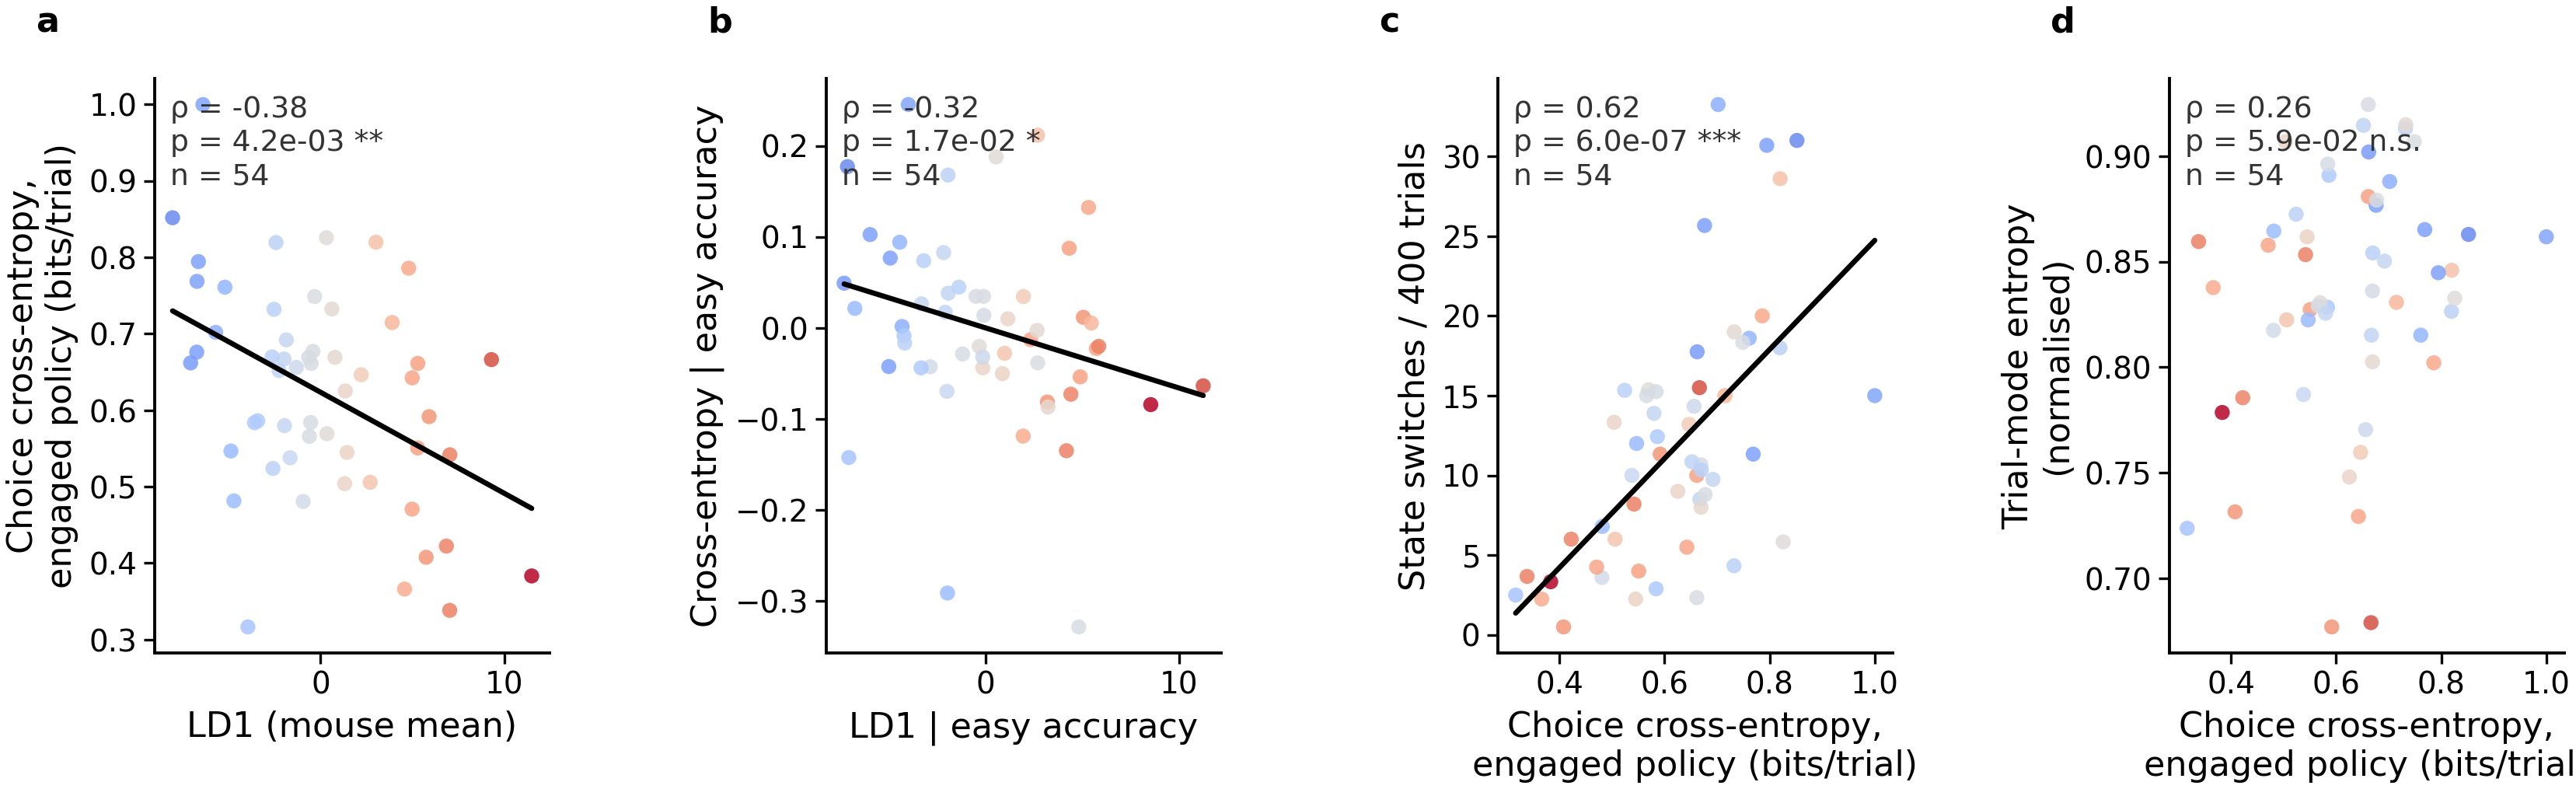

In [10]:
def av(m, x, y, covs):
    mm = m[[x, y] + covs].dropna()
    return (pd.Series(resid(mm[x].to_numpy(), [mm[c] for c in covs]), mm.index),
            pd.Series(resid(mm[y].to_numpy(), [mm[c] for c in covs]), mm.index))

col = ps.ld1_colors(M['lda_1'].to_numpy())
fig, axes = plt.subplots(1, 4, figsize=(10, 2.4), gridspec_kw=dict(wspace=0.7))
ps.corr_panel(axes[0], M['lda_1'], M['ce_engaged'], color=col, method='spearman',
              xlabel='LD1 (mouse mean)', ylabel='Choice cross-entropy,\nengaged policy (bits/trial)')
rx, ry = av(M, 'lda_1', 'ce_engaged', ['p_easy'])
ps.corr_panel(axes[1], rx, ry, color=ps.ld1_colors(M.loc[rx.index, 'lda_1'].to_numpy()), method='spearman',
              xlabel='LD1 | easy accuracy', ylabel='Cross-entropy | easy accuracy')
ps.corr_panel(axes[2], M['ce_engaged'], M['switches'], color=col, method='spearman',
              xlabel='Choice cross-entropy,\nengaged policy (bits/trial)', ylabel=f'State switches / {N_TRUNC} trials')
mm = M.dropna(subset=['H_modes'])
ps.corr_panel(axes[3], mm['ce_engaged'], mm['H_modes'], color=ps.ld1_colors(mm['lda_1'].to_numpy()), method='spearman',
              xlabel='Choice cross-entropy,\nengaged policy (bits/trial)', ylabel='Trial-mode entropy\n(normalised)')
for a, l in zip(axes, 'abcd'):
    a.text(-0.3, 1.08, l, transform=a.transAxes, fontweight='bold')
plt.show()

## 6. Lapses or sensitivity? A psychometric fit per mouse

Sections 2–3 point to easy-trial errors made against a sharp engaged policy, i.e. the classic psychometric **lapse**, not the **slope**. This tests that directly with no GLM-HMM.

Per mouse, pooled over its LDA sessions (first 400 trials each, 0.2/0.5/0.8 blocks): P(right) = γ + (1 − γ − λ) Φ((c − μ_block) / σ), with a threshold per block (`cp.psychometric_table`). **lapse** = γ + λ (errors at the asymptotes); **slope** = 1/σ (sensitivity). Mouse level, Spearman. Prediction: lapse tracks LD1 (more at the switchy end), slope does not, and lapse carries the switch–LD1 link.

In [11]:
psy = pd.read_parquet(cp.OUT / 'psychometric.parquet').set_index('mouse_name')
M = M.join(psy[['lapse', 'gamma', 'lam', 'slope', 'sigma']])
M['log_slope'] = np.log(M['slope'])
print(psy[['lapse', 'slope']].describe().round(3).T.to_string(), '\n')
print('lapse vs log slope (mice):', 'rho = %+.2f, p = %.3g' % tuple(spearmanr(M['lapse'], M['log_slope'])))
print(rho_table(S.merge(psy[['lapse', 'slope']], left_on='mouse_name', right_index=True), 'lda_1',
                ['lapse', 'slope']).round(3)[['n_mice', 'rho', 'p', 'rho_lab_centred', 'p_lab_centred']].to_string())
print()
for x, y, covs in [('lda_1', 'lapse', ['log_slope']), ('lda_1', 'log_slope', ['lapse']),
                   ('lda_1', 'switches', ['lapse']), ('lda_1', 'switches', ['lapse', 'log_slope']),
                   ('lda_1', 'ce_engaged', ['lapse']), ('lapse', 'switches', ['lda_1'])]:
    r, p, n = partial(M, x, y, covs)
    print(f"{y:11s} vs {x:6s} | {', '.join(covs):17s} rho = {r:+.3f}, p = {p:.3g}, n = {n}")

       count    mean    std    min    25%    50%     75%     max
lapse   56.0   0.072  0.045  0.000  0.039  0.068   0.098   0.213
slope   56.0  10.472  7.650  2.177  6.120  7.876  12.312  49.574 

lapse vs log slope (mice): rho = +0.13, p = 0.358
       n_mice    rho      p  rho_lab_centred  p_lab_centred
y                                                          
lapse      54 -0.385  0.004           -0.268          0.050
slope      54 -0.026  0.854           -0.034          0.808

lapse       vs lda_1  | log_slope         rho = -0.378, p = 0.00489, n = 54
log_slope   vs lda_1  | lapse             rho = +0.002, p = 0.988, n = 54
switches    vs lda_1  | lapse             rho = -0.163, p = 0.238, n = 54
switches    vs lda_1  | lapse, log_slope  rho = -0.164, p = 0.237, n = 54
ce_engaged  vs lda_1  | lapse             rho = -0.103, p = 0.46, n = 54
switches    vs lapse  | lda_1             rho = +0.602, p = 1.48e-06, n = 54


## 7. Lapses and reaction time: one trait or two?

RT level is LD1's strongest behavioural correlate (slow at the switchy end; RT spread is only the level shift, see project notes). If lapses and slowness are one trait, partialling one out should remove the other's link to LD1. `mean_log_rt`: mean log(first movement − go cue) per session over the first 400 trials, RT in (0.02, 10) s (`cp.rt_table`), averaged within mouse.

In [12]:
rt = pd.read_parquet(cp.OUT / 'reaction_times.parquet')
S = S.drop(columns=[c for c in ['mean_log_rt', 'sd_log_rt'] if c in S]).merge(rt, on='session', how='left')
M = M.join(S.groupby('mouse_name')[['mean_log_rt']].mean())
print(f"RT for {S['mean_log_rt'].notna().sum()} sessions")
print(rho_table(S, 'lda_1', ['mean_log_rt']).round(3).to_string())
print('lapse vs mean log RT (mice):', 'rho = %+.2f, p = %.3g' % tuple(spearmanr(*M[['lapse', 'mean_log_rt']].dropna().to_numpy().T)))
print()
for x, y, covs in [('lda_1', 'lapse', ['mean_log_rt']), ('lda_1', 'mean_log_rt', ['lapse']),
                   ('lda_1', 'switches', ['mean_log_rt']), ('lda_1', 'ce_engaged', ['mean_log_rt']),
                   ('lda_1', 'lapse', ['mean_log_rt', 'log_slope'])]:
    r, p, n = partial(M, x, y, covs)
    print(f"{y:11s} vs LD1 | {', '.join(covs):22s} rho = {r:+.3f}, p = {p:.3g}, n = {n}")

# lab-centred versions of the two key partials
L = M.dropna(subset=['lapse', 'mean_log_rt', 'lda_1']).copy()
for c in ['lda_1', 'lapse', 'mean_log_rt', 'log_slope']:
    L[c] = L[c] - L.groupby('lab')[c].transform('mean')
for y, cov in [('lapse', 'mean_log_rt'), ('mean_log_rt', 'lapse'), ('lapse', 'log_slope')]:
    r, p, n = partial(L, 'lda_1', y, [cov])
    print(f"lab-centred: {y:11s} vs LD1 | {cov:11s} rho = {r:+.3f}, p = {p:.3g}")

RT for 242 sessions
             n_mice    rho    p  rho_lab_centred  p_lab_centred  rho_within  p_within
y                                                                                    
mean_log_rt      54 -0.492  0.0           -0.402          0.003      -0.114     0.077
lapse vs mean log RT (mice): rho = +0.17, p = 0.209

lapse       vs LD1 | mean_log_rt            rho = -0.309, p = 0.0229, n = 54
mean_log_rt vs LD1 | lapse                  rho = -0.441, p = 0.000845, n = 54
switches    vs LD1 | mean_log_rt            rho = -0.296, p = 0.0298, n = 54
ce_engaged  vs LD1 | mean_log_rt            rho = -0.393, p = 0.00328, n = 54
lapse       vs LD1 | mean_log_rt, log_slope rho = -0.336, p = 0.0131, n = 54
lab-centred: lapse       vs LD1 | mean_log_rt rho = -0.261, p = 0.0565
lab-centred: mean_log_rt vs LD1 | lapse       rho = -0.364, p = 0.00688
lab-centred: lapse       vs LD1 | log_slope   rho = -0.268, p = 0.0497


## 8. Figure: lapse, slope and RT along LD1

(a) Mean psychometric curve (0.5 blocks) of the mice in each LD1 third: the curves should differ at the asymptotes, not in steepness. (b) lapse vs LD1, (c) slope vs LD1, (d) lapse vs LD1 with mean log RT partialled out of both (added-variable plot). Mouse level, coloured by LD1.

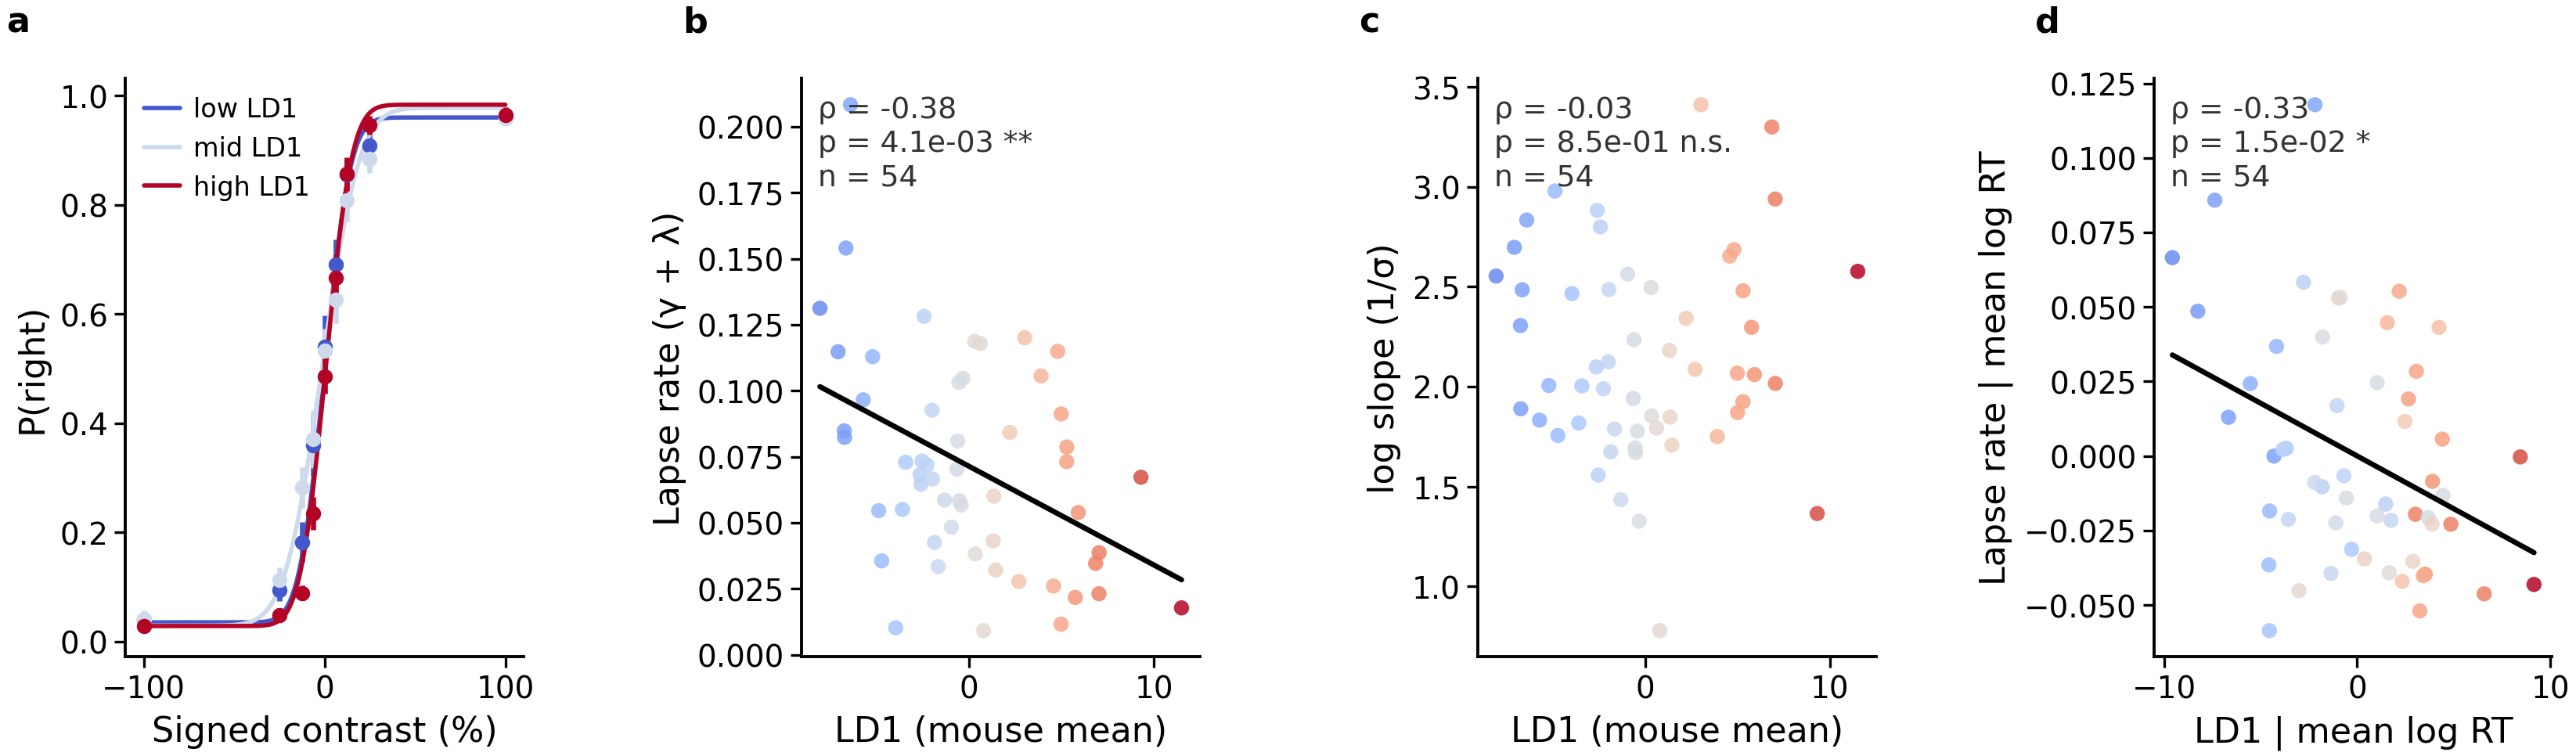

In [13]:
from scipy.stats import norm
M['third'] = pd.qcut(M['lda_1'], 3, labels=['low', 'mid', 'high'])
st_b = st[st['eid'].isin(S['session']) & (st['probabilityLeft'] == 0.5)].copy()
st_b['choice_right'] = ((st_b['contrastLeft'].isna() & (st_b['rewarded'] == 1))
                        | (st_b['contrastRight'].isna() & (st_b['rewarded'] == -1))).astype(float)
pm = (st_b.groupby(['animal', 'signed_contrast'])['choice_right'].mean().rename('p_right').reset_index()
          .merge(M['third'], left_on='animal', right_index=True))
THIRD_COLOR = dict(zip(['low', 'mid', 'high'], ps.ld1_colors(np.array([M['lda_1'].quantile(q) for q in (1/6, .5, 5/6)]))))

fig, axes = plt.subplots(1, 4, figsize=(10, 2.4), gridspec_kw=dict(wspace=0.7))
ax = axes[0]
xs = np.linspace(-1, 1, 201)
for t, g in pm.groupby('third', observed=True):
    agg = g.groupby('signed_contrast')['p_right'].agg(['mean', 'sem'])
    ax.errorbar(agg.index * 100, agg['mean'], yerr=agg['sem'], ls='none', marker='o', ms=2.5, color=THIRD_COLOR[t], capsize=0)
    f = psy.loc[M.index[M['third'] == t]].median(numeric_only=True)    # the median mouse's parameters, 0.5 block
    ax.plot(xs * 100, f['gamma'] + (1 - f['gamma'] - f['lam']) * norm.cdf((xs - f['mu_0.5']) / f['sigma']),
            color=THIRD_COLOR[t], lw=1, label=f'{t} LD1')
ax.set_xlabel('Signed contrast (%)'); ax.set_ylabel('P(right)'); ax.legend(frameon=False, fontsize=6, loc='upper left')
ps.corr_panel(axes[1], M['lda_1'], M['lapse'], color=ps.ld1_colors(M['lda_1'].to_numpy()), method='spearman',
              xlabel='LD1 (mouse mean)', ylabel='Lapse rate (γ + λ)')
ps.corr_panel(axes[2], M['lda_1'], M['log_slope'], color=ps.ld1_colors(M['lda_1'].to_numpy()), method='spearman',
              xlabel='LD1 (mouse mean)', ylabel='log slope (1/σ)')
rx, ry = av(M, 'lda_1', 'lapse', ['mean_log_rt'])
ps.corr_panel(axes[3], rx, ry, color=ps.ld1_colors(M.loc[rx.index, 'lda_1'].to_numpy()), method='spearman',
              xlabel='LD1 | mean log RT', ylabel='Lapse rate | mean log RT')
for a, l in zip(axes, 'abcd'):
    a.text(-0.3, 1.08, l, transform=a.transAxes, fontweight='bold')
plt.show()

## Summary

(LDA file `mouse_LDA_5_bins_raw_shrink0.5_wmouse_360_02-10-2026`: the switchy end is LOW LD1. 54 mice.)

1. **Choices at the switchy end stray more from the mouse's own engaged policy.** `ce_engaged` vs LD1: ρ = −0.38 (p = .004; lab-centred −0.37), the same size as switches (−0.38). It is carried by **easy trials** (ρ = −0.46); hard trials are null (−0.01), and zero-contrast trials lean the other way (+0.22, n.s.; within mouse +0.19, p = .003). So the difference is lapses on trials the engaged policy is sure about, not noisier evidence integration. Nothing is within mouse (|ρ| < 0.13).
2. **Beyond easy-trial accuracy it is borderline.** With `p_easy` partialled out: `ce_engaged` −0.27 (p = .051, rank partial; −0.32, p = .017 on raw residuals, panel b), `ce_engaged_easy` −0.31 (p = .022), switches −0.21 (p = .13 here, Spearman, 54 mice; `fig_engagement` reports p = .024 with Pearson, 52 mice). Under the mouse's held-out *average* policy (`ce_glm`) it is weaker (−0.24, p = .08) and gone after `p_easy` (+0.05). "Less stereotyped" therefore mostly means "lapses more on easy trials, relative to its own engaged policy". The part beyond accuracy is weak and depends on the estimator.
3. **It accounts for the switch count.** Switches vs `ce_engaged`: ρ = 0.62 across mice, 0.70 within mice. With `ce_engaged` partialled out, switches vs LD1 drops from −0.38 to −0.20 (n.s.). The switch–LD1 link is choice unpredictability restated.
4. **No link to syllable or trial-mode variability beyond LD1.** Mode entropy tracks LD1 (ρ = −0.35) and weakly tracks `ce_engaged` (+0.26, p = .06), but the partial on LD1 is ~0.1 (n.s.) for every choice measure, and within-mouse correlations are null. Syllable entropy is unrelated. As with switches (`fig_engagement_syllables` H): choice unpredictability and movement variability both line up with LD1, but not with each other.
5. **It is the lapse, not the slope (section 6).** Psychometric lapse (γ + λ) tracks LD1: ρ = −0.38 (p = .004). It is weaker lab-centred (−0.27, p = .05), so part of it is between labs. Slope is flat (−0.03), and the two are unrelated across mice (+0.13). Lapse survives controlling for slope (−0.38) and slope stays flat after controlling for lapse. Lapse carries the GLM-HMM link: switches vs lapse | LD1 is +0.60, and switches vs LD1 | lapse falls to −0.16 (n.s.); ce_engaged | lapse falls to −0.10. Panel a: the LD1 thirds' curves differ only at the asymptotes, and only slightly (a few % of high-contrast trials).
6. **Lapses and slow RTs are two separate LD1 correlates (section 7).** Mean log RT tracks LD1 more strongly (−0.49) and is unrelated to lapse across mice (+0.17, n.s.). Each survives the other: lapse vs LD1 | RT −0.31 (p = .02), RT vs LD1 | lapse −0.44 (p < .001); lapse | RT + slope −0.34 (p = .01). Lab-centred, the lapse partial is borderline (−0.26, p = .057) and the RT partial holds (−0.36, p = .007).

**In one line:** the GLM-HMM switchiness along LD1 is the psychometric lapse rate. It is separate from sensitivity and from the RT level, but it is moderate (ρ ≈ −0.3 to −0.4) and partly between labs.
